# 02 Factor Structure and Measurement Invariance

**Setting:** a 12-item customer satisfaction survey fielded in English
and Spanish. The business question: are Spanish-speaking customers more
satisfied with the product?
**Methods:** parallel analysis, exploratory factor analysis (principal
axis + promax), confirmatory factor analysis by maximum likelihood,
multi-group invariance testing (configural, metric, scalar), and a
search for partial invariance.
**Ground truth:** three factors with known loadings. The Spanish group
is truly 0.3 SD more satisfied with service and identical on the other
two factors. Two translated items, one about the product and one about
value, are simply easier to agree with (higher intercepts), which is a
measurement artifact, not satisfaction.

In [1]:
import sys, pathlib, warnings
warnings.filterwarnings("ignore")
_root = pathlib.Path.cwd()
if _root.name == "notebooks":
    _root = _root.parent
sys.path.insert(0, str(_root / "src"))
FIG_DIR = _root / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True,
                     "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False})
# Categorical slots (validated palette), plus ink for the known truth
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED = "#0b0b0b", "#8a8984"

In [2]:
from surveyhub.simulate import simulate_factor_data, simple_structure
from surveyhub.factor import (parallel_analysis, efa, congruence, fit_cfa,
                              invariance_sequence, locate_noninvariant_intercepts)

items = ["Product works as described", "Product is reliable", "Product is well made",
         "Product meets my needs", "Staff are helpful", "Issues resolved quickly",
         "Easy to reach support", "Staff are knowledgeable", "Fair price",
         "Worth what I pay", "Better value than rivals", "Would buy again"]
factors = ["Product", "Service", "Value"]
Lam = simple_structure([4, 4, 4], [.8, .75, .7, .65, .8, .7, .75, .6, .7, .8, .65, .6])
Phi = np.array([[1, .5, .4], [.5, 1, .45], [.4, .45, 1]])

en = simulate_factor_data(1200, Lam, Phi, seed=21)
nu_es = np.zeros(12)
nu_es[[1, 9]] = [0.6, 0.5]               # translation artifact: one product, one value item
true_kappa = np.array([0.0, 0.3, 0.0])  # the real difference: service only
es = simulate_factor_data(1200, Lam, Phi, nu=nu_es, kappa=true_kappa,
                          Theta=en.Theta, seed=22)
print("English n =", len(en.X), "  Spanish n =", len(es.X))

English n = 1200   Spanish n = 1200


## 1. How many factors? Parallel analysis

Keep a factor only if its eigenvalue beats what random, uncorrelated data
of the same size would produce (the 95th percentile over 200 simulated
datasets). This is far more reliable than the "eigenvalue above 1" rule.

In [3]:
pa = parallel_analysis(en.X, n_sims=200, seed=0)
print("factors retained:", pa.n_factors)
print("observed eigenvalues :", np.round(pa.observed[:5], 2))
print("random 95th pct      :", np.round(pa.threshold[:5], 2))

factors retained: 3
observed eigenvalues : [4.45 1.62 1.44 0.64 0.61]
random 95th pct      : [1.21 1.16 1.11 1.08 1.05]


## 2. Exploratory factor analysis

Principal axis factoring with an oblique (promax) rotation, since
satisfaction factors are expected to correlate. Tucker's congruence
compares each estimated factor with the true one (above 0.95 means the
factors are essentially the same).

In [4]:
res = efa(en.X, 3, rotation="promax")
c, aligned = congruence(res.loadings, Lam)
print(f"{'item':<28s}" + "".join(f"{f:>9s}" for f in factors) + "   true")
for i, name in enumerate(items):
    row = "".join(f"{v:9.2f}" for v in aligned[i])
    print(f"{name:<28s}{row}   {Lam[i].max():.2f} on {factors[Lam[i].argmax()]}")
print("\nTucker congruence per factor:", np.round(c, 3))

item                          Product  Service    Value   true
Product works as described       0.84    -0.03    -0.05   0.80 on Product
Product is reliable              0.77     0.02    -0.01   0.75 on Product
Product is well made             0.69     0.01     0.03   0.70 on Product
Product meets my needs           0.59    -0.01     0.04   0.65 on Product
Staff are helpful               -0.04     0.83    -0.00   0.80 on Service
Issues resolved quickly          0.02     0.67    -0.00   0.70 on Service
Easy to reach support           -0.01     0.71     0.06   0.75 on Service
Staff are knowledgeable          0.06     0.61    -0.04   0.60 on Service
Fair price                      -0.07     0.03     0.73   0.70 on Value
Worth what I pay                 0.00     0.01     0.79   0.80 on Value
Better value than rivals         0.04    -0.04     0.64   0.65 on Value
Would buy again                 -0.00     0.01     0.61   0.60 on Value

Tucker congruence per factor: [0.996 0.998 0.997]


## 3. Confirmatory factor analysis

Now fix the structure (each item loads only on its factor) and fit by
maximum likelihood. Fit indices: CFI and TLI near 1, RMSEA below 0.05
and SRMR below 0.08 indicate good fit.

In [5]:
pattern = Lam != 0
cfa_en = fit_cfa(en.X, pattern)
print("English CFA:", cfa_en.summary())
print("loading error vs truth (max abs):", np.abs(cfa_en.Lambda - Lam).max().round(3))
print("factor correlations:\n", np.round(cfa_en.Phi, 2))

English CFA: chi2(51) = 51.27, p = 0.463, CFI = 1.000, TLI = 1.000, RMSEA = 0.002, SRMR = 0.018
loading error vs truth (max abs): 0.051
factor correlations:
 [[1.   0.52 0.44]
 [0.52 1.   0.47]
 [0.44 0.47 1.  ]]


## 4. Invariance testing

Each step adds equality constraints across languages:

| Level | Constrained equal | What it licenses |
|---|---|---|
| Configural | same pattern | same constructs |
| Metric | + loadings | comparing relationships (correlations, slopes) |
| Scalar | + intercepts | comparing means |

A significant chi-square difference or a CFI drop larger than 0.01
means the constraint does not hold.

In [6]:
steps = invariance_sequence([en.X, es.X], pattern)
print(f"{'level':<11s} {'chi2':>8s} {'df':>4s} {'CFI':>6s} {'RMSEA':>6s} {'d chi2':>8s} {'d df':>5s} {'p':>9s} {'d CFI':>7s}")
for s in steps:
    print(f"{s.level:<11s} {s.fit.chi2:8.1f} {s.fit.df:4d} {s.fit.cfi:6.3f} {s.fit.rmsea:6.3f} "
          f"{s.delta_chi2:8.1f} {s.delta_df:5d} {s.p_diff:9.2g} {s.delta_cfi:+7.3f}")

level           chi2   df    CFI  RMSEA   d chi2  d df         p   d CFI
configural      86.7  102  1.000  0.000      nan     0       nan    +nan
metric          97.8  111  1.000  0.000     11.1     9      0.27  +0.000
scalar         577.5  120  0.952  0.056    479.8     9   1.2e-97  -0.048


Metric invariance holds; scalar does not. Before comparing means, find
which intercepts differ: release one at a time, keep the release that
improves fit most, and stop when no release is significant after a
Bonferroni correction.

In [7]:
freed, partial, log = locate_noninvariant_intercepts([en.X, es.X], pattern)
for step in log:
    print(f"release '{items[step['item']]}': d chi2 = {step['delta_chi2']:7.1f}, p = {step['p']:.2g}")
print("\nnon-invariant intercepts found:", [items[i] for i in freed])
print("planted:", [items[i] for i in np.flatnonzero(nu_es)])
print("partial scalar model:", partial.summary())

release 'Product is reliable': d chi2 =   297.2, p = 1.4e-66
release 'Worth what I pay': d chi2 =   175.1, p = 5.7e-40
release 'Would buy again': d chi2 =     2.9, p = 0.088

non-invariant intercepts found: ['Product is reliable', 'Worth what I pay']
planted: ['Product is reliable', 'Worth what I pay']
partial scalar model: chi2(118) = 105.28, p = 0.793, CFI = 1.000, TLI = 1.001, RMSEA = 0.000, SRMR = 0.019


## 5. The business question: who is more satisfied?

Three ways to compare languages, in SD units of the English group:

* **Naive:** difference in each factor's sum score (what a dashboard shows)
* **Full scalar:** latent mean difference with all intercepts equal
* **Partial scalar:** latent mean difference with the two artifact items freed

In [8]:
sums_en = np.column_stack([en.X[:, pattern[:, f]].sum(1) for f in range(3)])
sums_es = np.column_stack([es.X[:, pattern[:, f]].sum(1) for f in range(3)])
naive = (sums_es.mean(0) - sums_en.mean(0)) / sums_en.std(0, ddof=1)
full = steps[2].fit.groups[1].kappa
part = partial.groups[1].kappa
print(f"{'factor':<9s} {'truth':>7s} {'naive':>7s} {'full scalar':>12s} {'partial':>8s}")
for f in range(3):
    print(f"{factors[f]:<9s} {true_kappa[f]:7.2f} {naive[f]:7.2f} {full[f]:12.2f} {part[f]:8.2f}")

factor      truth   naive  full scalar  partial
Product      0.00    0.11         0.13    -0.07
Service      0.30    0.24         0.27     0.27
Value        0.00    0.12         0.24    -0.01


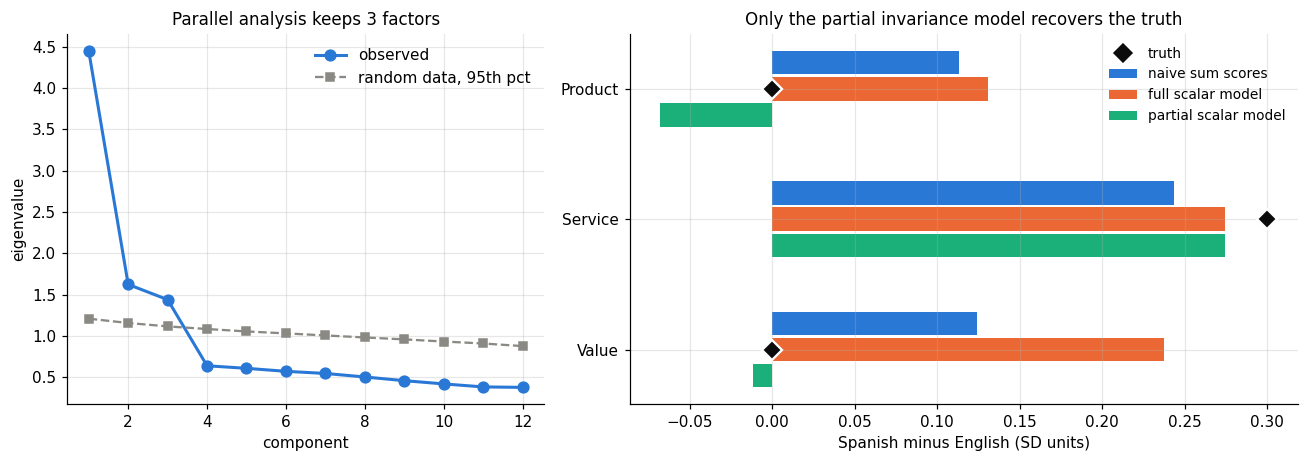

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.3), gridspec_kw={"width_ratios": [1, 1.4]})
k = np.arange(1, 13)
ax1.plot(k, pa.observed, "o-", color=BLUE, lw=2, ms=7, label="observed")
ax1.plot(k, pa.threshold, "s--", color=MUTED, lw=1.5, ms=5, label="random data, 95th pct")
ax1.set_xlabel("component")
ax1.set_ylabel("eigenvalue")
ax1.set_title("Parallel analysis keeps 3 factors", fontsize=11)
ax1.legend(frameon=False)

y = np.arange(3)
for off, vals, col, lab in [(-0.2, naive, BLUE, "naive sum scores"),
                            (0.0, full, ORANGE, "full scalar model"),
                            (0.2, part, AQUA, "partial scalar model")]:
    ax2.barh(y + off, vals, height=0.18, color=col, label=lab)
for f in range(3):
    ax2.plot(true_kappa[f], f, "D", color=INK, ms=9, markeredgecolor="white",
             markeredgewidth=1.5, zorder=5)
ax2.plot([], [], "D", color=INK, ms=8, label="truth")
ax2.set_yticks(y)
ax2.set_yticklabels(factors)
ax2.invert_yaxis()
ax2.set_xlabel("Spanish minus English (SD units)")
ax2.set_title("Only the partial invariance model recovers the truth", fontsize=11)
ax2.legend(frameon=False, loc="upper right", fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "invariance_latent_means.png", dpi=150, bbox_inches="tight")
plt.show()

## Takeaways

* Parallel analysis, EFA and CFA recover the three-factor structure from
  1,200 respondents.
* The naive dashboard comparison reports that Spanish-speaking customers
  are happier with the product and its value. They are not: two
  translated items are just easier to agree with. Forcing equal
  intercepts spreads that artifact into the latent means as well.
* Testing invariance, locating the non-invariant intercepts, and freeing
  them recovers the real finding: a service difference of about 0.3 SD
  and nothing else. Test invariance before comparing groups on any
  multi-item scale, especially across languages, modes, or cultures.
* Partial invariance needs most items on each factor to be invariant.
  If half of a factor's items shift, the data cannot tell which half is
  the anchor, and any search will pick one arbitrarily. Plan anchor items
  (carefully translated, pretested) into the questionnaire.